In [6]:
# Task 1: Load dataset

import pandas as rafay2
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

data = rafay2.read_csv("Mall_Customers.csv")

print(data.head())

   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


In [ ]:
# Task 2: Data preprocessing

x = data[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

c:\Users\Primax\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Primax\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Primax\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Users\Primax\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Wi

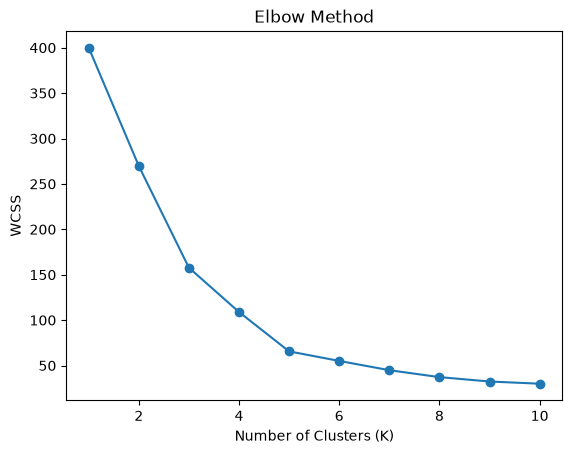

In [8]:
# Task 3: Find optimal K using Elbow Method

wcss = []

for k in range(1, 11):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    model.fit(x_scaled)

    wcss.append(model.inertia_)


plt.plot(range(1, 11), wcss, marker="o")

plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")

plt.show()

In [9]:
# Task 4: Apply K-Means

kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)

y_pred = kmeans.fit_predict(x_scaled)

data["Cluster"] = y_pred

print(data.head())

c:\Users\Primax\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


   CustomerID   Genre  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   

   Cluster  
0        4  
1        2  
2        4  
3        2  
4        4  


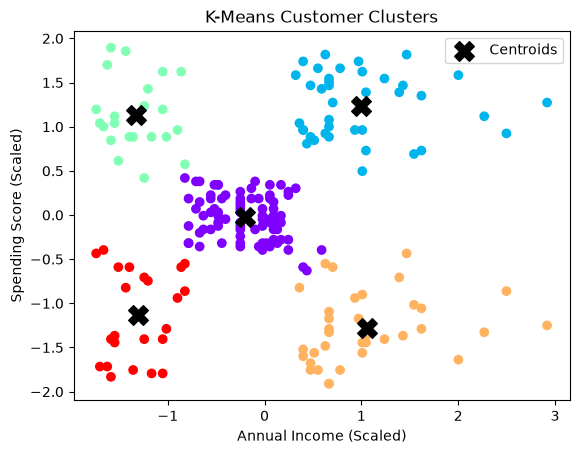

In [10]:

# Task 5: Visualize clusters

plt.scatter(
    x_scaled[:, 0],
    x_scaled[:, 1],
    c=y_pred,
    cmap="rainbow"
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color="black",
    marker="X",
    s=200,
    label="Centroids"
)

plt.title("K-Means Customer Clusters")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")
plt.legend()

plt.show()


In [ ]:
# Task 6: Evaluate clustering

score = silhouette_score(x_scaled, y_pred)

print("Silhouette Score:", score)

Silhouette Score: 0.5546571631111091
